In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score
from tensorflow.keras import Model, Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import MeanSquaredLogarithmicError
print("Libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)

Libraries imported successfully!
TensorFlow Version: 2.21.0


In [2]:
# ECG dataset URL
url = "http://storage.googleapis.com/download.tensorflow.org/data/ecg.csv"
# Load dataset
df = pd.read_csv(url)
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (4997, 141)


In [3]:
# Display first five rows
df.head()

,-0.11252183,-2.8272038,-3.7738969,-4.3497511,-4.376041,-3.4749863,-2.1814082,-1.8182865,-1.2505219,-0.47749208,...,0.79216787,0.93354122,0.79695779,0.57862066,0.2577399,0.22807718,0.12343082,0.92528624,0.19313742,1.0
0,-1.100878,-3.996840,-4.285843,-4.506579,-4.022377,-3.234368,-1.566126,-0.992258,-0.754680,0.042321,...,0.538356,0.656881,0.787490,0.724046,0.555784,0.476333,0.773820,1.119621,-1.436250,1.0
1,-0.567088,-2.593450,-3.874230,-4.584095,-4.187449,-3.151462,-1.742940,-1.490659,-1.183580,-0.394229,...,0.886073,0.531452,0.311377,-0.021919,-0.713683,-0.532197,0.321097,0.904227,-0.421797,1.0
2,0.490473,-1.914407,-3.616364,-4.318823,-4.268016,-3.881110,-2.993280,-1.671131,-1.333884,-0.965629,...,0.350816,0.499111,0.600345,0.842069,0.952074,0.990133,1.086798,1.403011,-0.383564,1.0
3,0.800232,-0.874252,-2.384761,-3.973292,-4.338224,-3.802422,-2.534510,-1.783423,-1.594450,-0.753199,...,1.148884,0.958434,1.059025,1.371682,1.277392,0.960304,0.971020,1.614392,1.421456,1.0
4,-1.507674,-3.574550,-4.478011,-4.408275,-3.321242,-2.105171,-1.481048,-1.301362,-0.498240,-0.286928,...,1.089068,0.983369,1.014124,0.952629,0.749326,1.007076,1.634990,1.493365,-0.783134,1.0


In [4]:
# Display dataset information
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("\nColumn names:")
print(df.columns)
print("\nMissing values:")
print(df.isnull().sum().sum())

Number of rows: 4997
Number of columns: 141

Column names:
Index(['-0.11252183', '-2.8272038', '-3.7738969', '-4.3497511', '-4.376041',
       '-3.4749863', '-2.1814082', '-1.8182865', '-1.2505219', '-0.47749208',
       ...
       '0.79216787', '0.93354122', '0.79695779', '0.57862066', '0.2577399',
       '0.22807718', '0.12343082', '0.92528624', '0.19313742', '1.0'],
      dtype='object', length=141)

Missing values:
0


In [5]:
# Separate features and target
features = df.iloc[:, :-1]
target = df.iloc[:, -1]
print("Features shape:", features.shape)
print("Target shape:", target.shape)
print("\nTarget classes:")
print(target.value_counts())

Features shape: (4997, 140)
Target shape: (4997,)

Target classes:
1.0
1.0    2918
0.0    2079
Name: count, dtype: int64


In [6]:
# Split dataset into training and testing data
x_train, x_test, y_train, y_test = train_test_split(
features,
target,
test_size=0.2,
stratify=target,
random_state=42
)
print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)


Training data shape: (3997, 140)
Testing data shape: (1000, 140)
Training target shape: (3997,)
Testing target shape: (1000,)


In [7]:
# Select only normal ECG samples for training
# Target class 1 represents normal ECG
x_train = x_train[y_train == 1]
print("Normal ECG training data shape:", x_train.shape)

Normal ECG training data shape: (2334, 140)


In [8]:
# Scale the ECG data between 0 and 1
scaler = MinMaxScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)
print("Training scaled data shape:", x_train_scaled.shape)
print("Testing scaled data shape:", x_test_scaled.shape)
print("Minimum value:", x_train_scaled.min())
print("Maximum value:", x_train_scaled.max())

Training scaled data shape: (2334, 140)
Testing scaled data shape: (1000, 140)
Minimum value: 0.0
Maximum value: 1.0000000000000002


In [10]:
# Create AutoEncoder using Keras Model class
class AutoEncoder(Model):
    def __init__(self, output_units):
        super().__init__()
        # Encoder - 4 layers
        self.encoder = Sequential([
            Dense(128, activation='relu'),
            Dense(64, activation='relu'),
            Dense(32, activation='relu'),
            Dense(16, activation='relu')
        ])
        # Decoder - 4 layers
        self.decoder = Sequential([
            Dense(32, activation='relu'),
            Dense(64, activation='relu'),
            Dense(128, activation='relu'),
            Dense(output_units, activation='sigmoid')
        ])
    def call(self, inputs):
        encoded = self.encoder(inputs)
        decoded = self.decoder(encoded)
        return decoded
print("AutoEncoder class created successfully!")

AutoEncoder class created successfully!


In [11]:
# Create Autoencoder model
model = AutoEncoder(output_units=x_train_scaled.shape[1])
print("Autoencoder model created successfully!")

Autoencoder model created successfully!


In [12]:
# Build the model
model.build(input_shape=(None, x_train_scaled.shape[1]))
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'auto_encoder', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


Model: "auto_encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [13]:
# Compile the Autoencoder
model.compile(
optimizer=Adam(),
loss=MeanSquaredLogarithmicError(),
metrics=['mse']
)
print("Model compiled successfully!")


Model compiled successfully!


In [14]:
# Train the Autoencoder
history = model.fit(
x_train_scaled,
x_train_scaled,
epochs=20,
batch_size=512,
validation_data=(x_test_scaled, x_test_scaled),
verbose=1
)

Epoch 1/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 110ms/step - loss: 0.0110 - mse: 0.0248 - val_loss: 0.0134 - val_mse: 0.0311
Epoch 2/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 0.0105 - mse: 0.0236 - val_loss: 0.0129 - val_mse: 0.0299
Epoch 3/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 0.0089 - mse: 0.0200 - val_loss: 0.0126 - val_mse: 0.0290
Epoch 4/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0071 - mse: 0.0158 - val_loss: 0.0127 - val_mse: 0.0292
Epoch 5/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0058 - mse: 0.0128 - val_loss: 0.0115 - val_mse: 0.0265
Epoch 6/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0051 - mse: 0.0112 - val_loss: 0.0116 - val_mse: 0.0268
Epoch 7/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0047 - mse: 0.0104 - val_loss: 0.0108 - val_mse: 0.0250
Epoch 8/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0045 - mse: 0.0099 - val_loss: 0.0104 - val_mse: 0.0242
Epoch 9/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0043 - mse: 0.0095 -

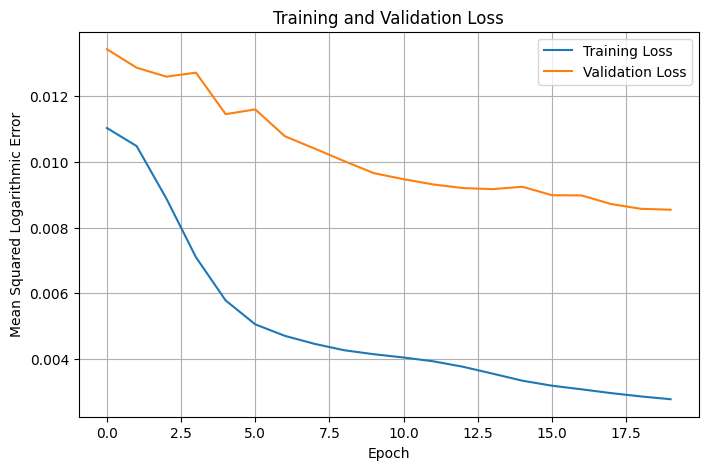

In [15]:
# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Logarithmic Error')
plt.legend()
plt.grid()
plt.show()


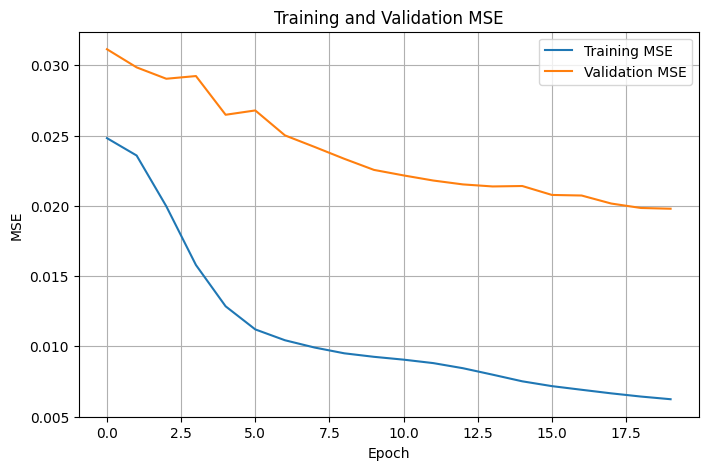

In [16]:
# Plot training and validation MSE
plt.figure(figsize=(8, 5))
plt.plot(history.history['mse'], label='Training MSE')
plt.plot(history.history['val_mse'], label='Validation MSE')
plt.title('Training and Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()
plt.grid()
plt.show()

In [17]:
# Reconstruct training ECG signals
train_reconstructions = model.predict(x_train_scaled, verbose=0)
print("Reconstruction shape:", train_reconstructions.shape)


Reconstruction shape: (2334, 140)


In [18]:
# Calculate reconstruction errors for training data
reconstruction_errors = tf.keras.losses.msle(
x_train_scaled,
train_reconstructions
)
print("Reconstruction errors calculated successfully!")
print("Mean reconstruction error:",
np.mean(reconstruction_errors.numpy()))
print("Maximum reconstruction error:",
np.max(reconstruction_errors.numpy()))

Reconstruction errors calculated successfully!
Mean reconstruction error: 0.0027302862
Maximum reconstruction error: 0.046277348


In [19]:
# Calculate anomaly threshold
threshold = (
np.mean(reconstruction_errors.numpy())
+ np.std(reconstruction_errors.numpy())
)
print("Anomaly Threshold:", threshold)


Anomaly Threshold: 0.006171178


In [20]:
# Reconstruct test ECG signals
test_reconstructions = model.predict(
x_test_scaled,
verbose=0
)
# Calculate reconstruction errors for test data
test_reconstruction_errors = tf.keras.losses.msle(
x_test_scaled,
test_reconstructions
)
print("Test reconstruction errors calculated!")


Test reconstruction errors calculated!


In [21]:
# Predict anomalies using threshold
predicted_labels = (
test_reconstruction_errors.numpy() > threshold
).astype(int)
print("Predictions generated successfully!")
print("First 20 predictions:")
print(predicted_labels[:20])


Predictions generated successfully!
First 20 predictions:
[0 0 1 1 0 0 1 0 1 0 0 1 1 0 1 1 0 0 1 1]


In [22]:
# Calculate accuracy score
accuracy = accuracy_score(
y_test,
predicted_labels
)
print("Accuracy Score:", accuracy)
print("Accuracy Percentage:", accuracy * 100)

Accuracy Score: 0.044
Accuracy Percentage: 4.3999999999999995


In [23]:
from sklearn.metrics import confusion_matrix, classification_report
# Confusion Matrix
cm = confusion_matrix(y_test, predicted_labels)
print("Confusion Matrix:")
print(cm)
print("\nClassification Report:")
print(
classification_report(
y_test,
predicted_labels,
target_names=['Anomaly', 'Normal']
)
)

Confusion Matrix:
[[  0 416]
 [540  44]]

Classification Report:
              precision    recall  f1-score   support

     Anomaly       0.00      0.00      0.00       416
      Normal       0.10      0.08      0.08       584

    accuracy                           0.04      1000
   macro avg       0.05      0.04      0.04      1000
weighted avg       0.06      0.04      0.05      1000



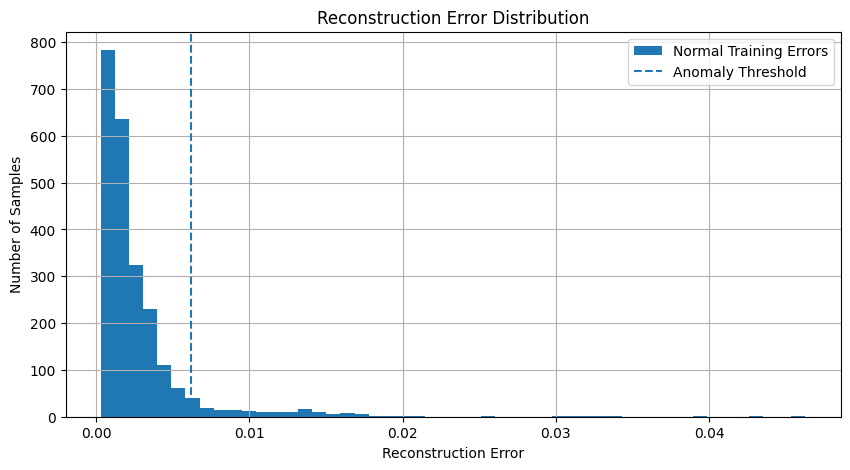

In [24]:
# Plot reconstruction errors
plt.figure(figsize=(10, 5))
plt.hist(
reconstruction_errors.numpy(),
bins=50,
label='Normal Training Errors'
)
plt.axvline(
threshold,
linestyle='--',
label='Anomaly Threshold'
)
plt.title('Reconstruction Error Distribution')
plt.xlabel('Reconstruction Error')
plt.ylabel('Number of Samples')
plt.legend()
plt.grid()
plt.show()


In [26]:
# Display final results
print("=" * 50)
print("ECG ANOMALY DETECTION - FINAL RESULTS")
print("=" * 50)
print(f"Training Samples : {len(x_train_scaled)}")
print(f"Testing Samples : {len(x_test_scaled)}")
print(f"Anomaly Threshold : {threshold:.6f}")
print(f"Accuracy Score : {accuracy:.4f}")
print(f"Accuracy Percentage : {accuracy * 100:.2f}%")
print("=" * 50)

ECG ANOMALY DETECTION - FINAL RESULTS
Training Samples : 2334
Testing Samples : 1000
Anomaly Threshold : 0.006171
Accuracy Score : 0.0440
Accuracy Percentage : 4.40%


In [27]:
# Count predicted normal and anomalous ECG signals
normal_count = np.sum(predicted_labels == 0)
anomaly_count = np.sum(predicted_labels == 1)
print("Predicted Normal ECGs :", normal_count)
print("Predicted Anomalous ECGs :", anomaly_count)

Predicted Normal ECGs : 540
Predicted Anomalous ECGs : 460
